# **DSMBC Online Shoppers Intention: Modelling**

Notebook ini melanjutkan `DSMBC_Online_Shoppers_Preprocessing.ipynb`. Tujuannya melatih beberapa model untuk memprediksi `Revenue` (apakah sesi berakhir dengan pembelian), membandingkannya secara adil, dan menjelaskan **mengapa** tiap model dipilih.

**Isi notebook**

| Bagian | Isi |
|---|---|
| 1 | Persiapan, data, dan pembagian latih/uji (identik dengan notebook preprocessing) |
| 2 | Sistem checkpoint untuk Google Colab |
| 3 | Mengapa model-model ini |
| 4 | Pencarian hiperparameter per model (dengan checkpoint tiap kandidat) |
| 5 | Pelatihan akhir, ensemble, dan pemilihan ambang keputusan |
| 6 | Evaluasi pada data uji (sekali saja) |
| 7 | Uji tanpa `PageValues` dan interpretasi model |
| 8 | Menyimpan hasil dan kesimpulan |

**Aturan yang dijaga di seluruh notebook**
- Data uji **tidak dipakai** untuk memilih model, hiperparameter, maupun ambang. Semua pilihan memakai cross-validation (CV) pada data latih.
- Preprocessing berada **di dalam pipeline**, jadi dipelajari ulang di tiap fold dan tidak ada kebocoran.
- Metrik utama: **PR-AUC** (*average precision*). Hanya 15,6% sesi yang membeli, dan PR-AUC fokus pada kelas pembeli. ROC-AUC bisa terlihat bagus walau kelas minoritas buruk, jadi dipakai sebagai pendamping.

# **1. PERSIAPAN, DATA, DAN PEMBAGIAN**

Langkah ini mengulang notebook preprocessing (konversi boolean, buang duplikat, split 80/20 *stratified* dengan seed 42) supaya notebook ini bisa dijalankan sendiri dan pembagian datanya **persis sama**.

In [1]:
import os, sys, json, time, hashlib, warnings, subprocess, zipfile, shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# XGBoost dan LightGBM biasanya sudah ada di Colab; pasang bila belum
for paket in ("xgboost", "lightgbm"):
    try:
        __import__(paket)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paket])

from sklearn.model_selection import (train_test_split, StratifiedKFold, ParameterSampler,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)
from scipy.stats import loguniform
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 130)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (8, 5)

# ---------------- Pengaturan yang boleh diubah ----------------
RANDOM_STATE = 42
CV_FOLDS     = 5       # jumlah fold untuk tuning dan prediksi out-of-fold
N_ITER       = 12      # kandidat hiperparameter per model. Naikkan (mis. 30) bila waktu Colab cukup
USE_DRIVE    = True    # True: simpan checkpoint ke Google Drive agar selamat dari disconnect
DRIVE_FOLDER = "DSMBC_checkpoints"
# ---------------------------------------------------------------
print("sklearn siap. N_ITER =", N_ITER, "| CV_FOLDS =", CV_FOLDS)

sklearn siap. N_ITER = 12 | CV_FOLDS = 5


In [2]:
# Muat data dan ulangi langkah dari notebook preprocessing: konversi boolean, buang duplikat, split 80/20 stratified
url = "https://raw.githubusercontent.com/Roun-02/DSMBC-Online-Shoppers-Intention/refs/heads/main/online_shoppers_intention.csv"
local_candidates = ["online_shoppers_intention.csv", "data/online_shoppers_intention.csv"]
path = next((p for p in local_candidates if os.path.exists(p)), url)
df = pd.read_csv(path)

num_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
            'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
nominal_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']
MIN_FREQ = 100
target = 'Revenue'

df[target] = df[target].astype(int)
df['Weekend'] = df['Weekend'].astype(int)
df_clean = df.drop_duplicates().reset_index(drop=True)

X = df_clean.drop(columns=target)
y = df_clean[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Pembagian harus identik dengan notebook preprocessing (9.764 latih, 2.441 uji)
assert len(X_train) == 9764 and len(X_test) == 2441, "Ukuran data tidak sama dengan notebook preprocessing"

print("Sumber data:", path)
print("Data mentah:", df.shape, "| setelah buang duplikat:", df_clean.shape)
print("Latih:", X_train.shape, "| Uji:", X_test.shape)
print(f"Proporsi pembeli  latih {y_train.mean():.4f} | uji {y_test.mean():.4f}")

Sumber data: https://raw.githubusercontent.com/Roun-02/DSMBC-Online-Shoppers-Intention/refs/heads/main/online_shoppers_intention.csv
Data mentah: (12330, 18) | setelah buang duplikat: (12205, 18)
Latih: (9764, 17) | Uji: (2441, 17)
Proporsi pembeli  latih 0.1563 | uji 0.1565


In [3]:
log_tf = FunctionTransformer(np.log1p, feature_names_out='one-to-one')

def make_preprocessor(branch='linear', drop_pagevalues=False):
    """Sama dengan notebook preprocessing.
    linear: log1p + StandardScaler, BounceRates dilepas (untuk Logistic Regression).
    tree  : fitur numerik mentah (model pohon tidak butuh transformasi, lihat bagian 8.7 notebook preprocessing)."""
    num = list(num_cols)
    if drop_pagevalues:
        num.remove('PageValues')
    if branch == 'linear':
        num.remove('BounceRates')
        skew = [c for c in num if c != 'SpecialDay']
        numeric = [('num_skew', Pipeline([('log', log_tf), ('scale', StandardScaler())]), skew),
                   ('num_lain', StandardScaler(), ['SpecialDay'])]
    else:
        numeric = [('num', 'passthrough', num)]
    categorical = [
        ('nominal', OneHotEncoder(min_frequency=MIN_FREQ, handle_unknown='infrequent_if_exist', sparse_output=False), nominal_cols),
        ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Month', 'VisitorType']),
        ('biner', 'passthrough', ['Weekend']),
    ]
    return ColumnTransformer(numeric + categorical, verbose_feature_names_out=False).set_output(transform='pandas')

print("Jalur linear:", make_preprocessor('linear').fit_transform(X_train).shape,
      "| jalur pohon:", make_preprocessor('tree').fit_transform(X_train).shape)

Jalur linear: (9764, 57) | jalur pohon: (9764, 58)


# **2. SISTEM CHECKPOINT (UNTUK GOOGLE COLAB)**

Sesi Colab bisa terputus (idle, batas waktu, GPU/RAM habis). Tanpa checkpoint, seluruh pelatihan harus diulang dari nol. Di notebook ini **setiap potongan kerja disimpan begitu selesai**.

**Apa yang disimpan dan kapan**

| File | Isi | Dibuat saat |
|---|---|---|
| `cari_<model>.jsonl` | Satu baris per kandidat hiperparameter yang selesai di-CV (parameter, skor tiap fold, waktu) | Setiap **kandidat** selesai |
| `model_<model>.joblib` | Model terbaik yang sudah dilatih pada seluruh data latih | Pelatihan akhir selesai |
| `oof_<model>.npy` | Probabilitas *out-of-fold* (dipakai memilih ambang dan membuat ensemble) | Prediksi OOF selesai |
| `ablasi_<model>.json` | Skor CV tanpa `PageValues` | Uji ablasi selesai |
| `hasil/` | Tabel hasil akhir dan model terbaik | Bagian 8 |

**Cara melanjutkan setelah terputus:** buka lagi notebook, jalankan **Runtime → Run all** (atau sel dari atas). Sel yang pekerjaannya sudah tersimpan akan mencetak `[SKIP]` dan langsung lewat. Kandidat yang sedang berjalan saat putus diulang dari awal kandidat itu saja; kandidat sebelumnya tidak diulang.

**Pengaman:**
- Penulisan **atomik** (tulis ke file sementara, lalu ganti nama), jadi file tidak rusak setengah jalan bila sesi mati saat menulis.
- Folder checkpoint diberi `RUN_ID` dari hash pengaturan (seed, `N_ITER`, jumlah fold, ukuran data, daftar model). Bila pengaturan diubah, folder baru dibuat dan hasil lama tidak tercampur.
- Bila Google Drive tidak bisa di-mount, checkpoint disimpan di folder lokal Colab (`./checkpoints`). Itu **hilang** bila runtime direset, jadi pakai Drive untuk pelatihan panjang.

In [4]:
# Tentukan lokasi checkpoint (Google Drive bila di Colab, jika tidak folder lokal)
def siapkan_root_checkpoint():
    root = "./checkpoints"
    if USE_DRIVE:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            root = f"/content/drive/MyDrive/{DRIVE_FOLDER}"
        except ImportError:
            print("Bukan Google Colab: checkpoint disimpan lokal di ./checkpoints")
        except Exception as e:
            print("Drive gagal di-mount, pakai folder lokal (hilang bila runtime direset):", e)
    return root

NAMA_MODEL = ["Logistic Regression", "Random Forest", "HistGradientBoosting", "XGBoost", "LightGBM"]
konfigurasi_run = {"seed": RANDOM_STATE, "n_iter": N_ITER, "cv": CV_FOLDS, "n_train": len(X_train),
                   "n_test": len(X_test), "model": NAMA_MODEL}
RUN_ID = hashlib.md5(json.dumps(konfigurasi_run, sort_keys=True).encode()).hexdigest()[:8]
CKPT_DIR = os.path.join(siapkan_root_checkpoint(), f"run_{RUN_ID}")
os.makedirs(CKPT_DIR, exist_ok=True)

def slug(nama):
    return nama.lower().replace(" ", "_")

def tulis_atomik(path, fungsi_tulis):
    tmp = path + ".tmp"
    fungsi_tulis(tmp)
    os.replace(tmp, path)          # atomik: file lama utuh sampai file baru lengkap

def simpan_json(path, obj):
    def f(p):
        with open(p, "w") as h:
            json.dump(obj, h, indent=1)
    tulis_atomik(path, f)

def muat_json(path):
    with open(path) as h:
        return json.load(h)

def simpan_joblib(path, obj):
    tulis_atomik(path, lambda p: joblib.dump(obj, p))

def simpan_npy(path, arr):
    def f(p):
        with open(p, "wb") as h:
            np.save(h, arr)
    tulis_atomik(path, f)

def tambah_jsonl(path, obj):
    with open(path, "a") as h:
        h.write(json.dumps(obj) + "\n"); h.flush(); os.fsync(h.fileno())

def baca_jsonl(path):
    baris = []
    if os.path.exists(path):
        with open(path) as h:
            for teks in h:
                try:
                    baris.append(json.loads(teks))
                except json.JSONDecodeError:
                    break          # baris terakhir terpotong akibat sesi mati: abaikan, kandidat itu diulang
    return baris

def bersihkan(p):
    """Ubah nilai numpy menjadi tipe Python biasa agar bisa disimpan sebagai JSON."""
    return {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}

def status_checkpoint():
    rows = [{"file": f, "ukuran_KB": round(os.path.getsize(os.path.join(CKPT_DIR, f)) / 1024, 1)}
            for f in sorted(os.listdir(CKPT_DIR)) if os.path.isfile(os.path.join(CKPT_DIR, f))]
    return pd.DataFrame(rows)

print("Folder checkpoint:", CKPT_DIR)
print("RUN_ID:", RUN_ID, "| file tersimpan saat ini:", len(status_checkpoint()))

Bukan Google Colab: checkpoint disimpan lokal di ./checkpoints
Folder checkpoint: ./checkpoints/run_3820ee67
RUN_ID: 3820ee67 | file tersimpan saat ini: 0


# **3. MENGAPA MODEL-MODEL INI**

Data ini **tabular**, berukuran kecil (±9,7 ribu baris latih), bercampur fitur numerik miring, kategori, dan biner, dengan kelas pembeli 15,6%. Pemilihan model mengikuti ciri itu.

| Model | Jenis | Alasan dipilih | Jalur preprocessing |
|---|---|---|---|
| **Dummy (prior)** | Pembanding | Batas bawah. Model yang tidak melampaui PR-AUC ≈ proporsi pembeli (0,156) tidak berguna. | – |
| **Logistic Regression** | Linear | Baseline yang cepat dan **koefisiennya bisa dibaca** (arah dan besar pengaruh tiap fitur). Preprocessing `log1p` + scaling memang disiapkan untuknya. Bobot kelas dimasukkan ke ruang pencarian karena di notebook preprocessing (8.6) efeknya belum jelas. | linear |
| **Random Forest** | Ensemble bagging | Merata-ratakan banyak pohon dalam sehingga menangkap **interaksi dan hubungan non-linear** (mis. `PageValues` dengan `VisitorType` atau bulan) tanpa scaling, tahan terhadap outlier, dan jarang overfit parah. Mewakili keluarga *bagging*. | pohon |
| **HistGradientBoosting** | Boosting (sklearn) | Pada notebook preprocessing 8.5 sudah memberi PR-AUC ≈ 0,729 **tanpa tuning**, jauh di atas Logistic Regression (≈ 0,664). Cepat dan tidak butuh paket tambahan. | pohon |
| **XGBoost** | Boosting | Standar industri untuk data tabular. Punya regularisasi L1/L2 eksplisit dan `scale_pos_weight` untuk kelas tidak seimbang. | pohon |
| **LightGBM** | Boosting | Pohon tumbuh per daun (*leaf-wise*), lebih cepat, dan algoritma pencarian split yang berbeda dari XGBoost, jadi layak dibandingkan. | pohon |
| **Soft voting (3 terbaik)** | Ensemble | Merata-ratakan probabilitas tiga model dengan skor CV tertinggi untuk meredam varians. Hanya dipakai bila terbukti lebih baik. | – |

**Mengapa bukan model lain?**
- *SVM kernel*: lambat untuk ribuan baris dan probabilitasnya tidak terkalibrasi tanpa langkah tambahan.
- *KNN*: sensitif terhadap skala dan dimensi one-hot, serta lambat saat prediksi.
- *Jaringan saraf*: untuk data tabular sekecil ini biasanya tidak mengalahkan *gradient boosting*, tetapi lebih sulit disetel dan dijelaskan.

**Mengapa tuning dengan pencarian acak?** Ruang hiperparameter boosting besar. *Random search* dengan jumlah kandidat tetap menjangkau ruang itu lebih efisien daripada *grid search* dengan biaya yang sama, dan karena kandidatnya dibangkitkan dengan seed tetap, daftar kandidat identik tiap kali dijalankan. Itulah yang membuat checkpoint per kandidat bisa dipakai ulang.

In [5]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
rasio_neg_pos = (y_train == 0).sum() / (y_train == 1).sum()      # ≈ 5,4 : 1, untuk scale_pos_weight

def ambang_f1_terbaik(y_true, proba):
    """Ambang yang memaksimalkan F1. Dipilih dari prediksi out-of-fold (data latih), bukan dari data uji."""
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.argmax(f1)])

def metrik(y_true, proba, ambang):
    pred = (proba >= ambang).astype(int)
    return {"PR-AUC": average_precision_score(y_true, proba), "ROC-AUC": roc_auc_score(y_true, proba),
            "ambang": ambang, "precision": precision_score(y_true, pred), "recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred)}

# Pembanding paling sederhana
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
pr_dummy = average_precision_score(y_test, dummy.predict_proba(X_test)[:, 1])
print(f"PR-AUC tebakan acak (prior) pada data uji = {pr_dummy:.4f} (= proporsi pembeli). Semua model harus jauh di atas ini.")

PR-AUC tebakan acak (prior) pada data uji = 0.1565 (= proporsi pembeli). Semua model harus jauh di atas ini.


In [6]:
# Daftar model, jalur preprocessing, dan ruang pencarian hiperparameter
MODELS = {
    "Logistic Regression": dict(
        branch="linear",
        est=lambda: LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        space={"C": loguniform(1e-3, 1e2), "class_weight": [None, "balanced"]}),
    "Random Forest": dict(
        branch="tree",
        est=lambda: RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
        space={"n_estimators": [150, 250, 400], "max_depth": [None, 6, 10, 16],
               "min_samples_leaf": [1, 3, 5, 10], "max_features": ["sqrt", 0.3, 0.5],
               "class_weight": [None, "balanced_subsample"]}),
    "HistGradientBoosting": dict(
        branch="tree",
        est=lambda: HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE),
        space={"learning_rate": loguniform(0.02, 0.3), "max_iter": [100, 200, 300],
               "max_leaf_nodes": [8, 15, 31], "min_samples_leaf": [20, 40, 80],
               "l2_regularization": loguniform(1e-3, 10), "class_weight": [None, "balanced"]}),
    "XGBoost": dict(
        branch="tree",
        est=lambda: XGBClassifier(tree_method="hist", eval_metric="aucpr", random_state=RANDOM_STATE, n_jobs=-1, verbosity=0),
        space={"n_estimators": [150, 250, 400], "learning_rate": loguniform(0.02, 0.2),
               "max_depth": [2, 3, 4, 6], "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.7, 1.0],
               "min_child_weight": [1, 3, 5], "reg_lambda": loguniform(0.1, 10),
               "scale_pos_weight": [1.0, round(float(rasio_neg_pos), 3)]}),
    "LightGBM": dict(
        branch="tree",
        est=lambda: LGBMClassifier(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        space={"n_estimators": [150, 250, 400], "learning_rate": loguniform(0.02, 0.2),
               "num_leaves": [8, 15, 31], "min_child_samples": [20, 40, 80], "subsample": [0.6, 0.8, 1.0],
               "colsample_bytree": [0.5, 0.7, 1.0], "reg_lambda": loguniform(0.1, 10),
               "class_weight": [None, "balanced"]}),
}
assert list(MODELS) == NAMA_MODEL

def buat_pipeline(nama, params=None, drop_pagevalues=False):
    cfg = MODELS[nama]
    clf = cfg["est"]()
    if params:
        clf.set_params(**params)
    return Pipeline([("prep", make_preprocessor(cfg["branch"], drop_pagevalues)), ("clf", clf)])

print({k: len(v["space"]) for k, v in MODELS.items()}, "<- jumlah hiperparameter yang dicari per model")

{'Logistic Regression': 2, 'Random Forest': 5, 'HistGradientBoosting': 6, 'XGBoost': 8, 'LightGBM': 8} <- jumlah hiperparameter yang dicari per model


# **4. PENCARIAN HIPERPARAMETER (DENGAN CHECKPOINT)**

Untuk tiap model, `N_ITER` kandidat hiperparameter dibangkitkan secara acak (seed tetap), lalu masing-masing dinilai dengan **CV 5-fold pada data latih** memakai PR-AUC. Hasil tiap kandidat langsung ditulis ke `cari_<model>.jsonl`.

Bila sesi terputus lalu sel ini dijalankan lagi, kandidat yang sudah tercatat dilewati dan pencarian lanjut dari kandidat berikutnya.

In [7]:
def cari_hiperparameter(nama):
    cfg = MODELS[nama]
    path = os.path.join(CKPT_DIR, f"cari_{slug(nama)}.jsonl")
    kandidat = [bersihkan(p) for p in ParameterSampler(cfg["space"], n_iter=N_ITER, random_state=RANDOM_STATE)]

    tercatat = baca_jsonl(path)
    # Pengaman: bila daftar kandidat tersimpan tidak sama dengan yang dibangkitkan sekarang (mis. versi library berbeda), mulai ulang
    if any(r["idx"] >= len(kandidat) or r["params"] != kandidat[r["idx"]] for r in tercatat):
        os.replace(path, path + ".bak"); tercatat = []
        print(f"[{nama}] checkpoint lama tidak cocok dengan kandidat sekarang, dimulai ulang (arsip: .bak)")
    selesai = {r["idx"] for r in tercatat}

    if len(selesai) == len(kandidat):
        print(f"[SKIP] {nama}: {len(kandidat)}/{len(kandidat)} kandidat sudah ada di checkpoint")
    elif selesai:
        print(f"[LANJUT] {nama}: {len(selesai)}/{len(kandidat)} kandidat sudah ada, melanjutkan dari sana")
    else:
        print(f"[MULAI] {nama}: {len(kandidat)} kandidat")

    for i, params in enumerate(kandidat):
        if i in selesai:
            continue
        t0 = time.time()
        r = cross_validate(buat_pipeline(nama, params), X_train, y_train, cv=cv,
                           scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
        tambah_jsonl(path, {"idx": i, "params": params, "pr_auc_fold": r["test_pr_auc"].tolist(),
                            "roc_auc": float(r["test_roc_auc"].mean()), "detik": round(time.time() - t0, 1)})
        print(f"   kandidat {i + 1:>2}/{len(kandidat)}  PR-AUC CV = {r['test_pr_auc'].mean():.4f} (±{r['test_pr_auc'].std():.4f})  [{time.time() - t0:.1f} dtk]")

    df_hasil = pd.DataFrame(baca_jsonl(path))
    df_hasil["pr_auc"] = df_hasil["pr_auc_fold"].apply(np.mean)
    df_hasil["pr_auc_std"] = df_hasil["pr_auc_fold"].apply(np.std)
    return df_hasil.sort_values("pr_auc", ascending=False).reset_index(drop=True)

hasil_cari = {}
t_mulai = time.time()
for nama in MODELS:
    hasil_cari[nama] = cari_hiperparameter(nama)
print(f"\nSelesai. Waktu sel ini: {(time.time() - t_mulai) / 60:.1f} menit")

[MULAI] Logistic Regression: 12 kandidat


   kandidat  1/12  PR-AUC CV = 0.6854 (±0.0194)  [0.4 dtk]


   kandidat  2/12  PR-AUC CV = 0.6672 (±0.0193)  [0.4 dtk]


   kandidat  3/12  PR-AUC CV = 0.6830 (±0.0198)  [0.4 dtk]


   kandidat  4/12  PR-AUC CV = 0.6844 (±0.0199)  [0.4 dtk]


...

   kandidat  8/12  PR-AUC CV = 0.7436 (±0.0231)  [1.5 dtk]


   kandidat  9/12  PR-AUC CV = 0.7330 (±0.0159)  [1.6 dtk]


   kandidat 10/12  PR-AUC CV = 0.7497 (±0.0174)  [1.2 dtk]


   kandidat 11/12  PR-AUC CV = 0.7354 (±0.0220)  [0.8 dtk]


   kandidat 12/12  PR-AUC CV = 0.7380 (±0.0204)  [1.3 dtk]

Selesai. Waktu sel ini: 3.7 menit


,PR-AUC CV (terbaik),std antar fold,ROC-AUC CV,PR-AUC kandidat terburuk,rata-rata waktu/kandidat (dtk)
HistGradientBoosting,0.7551,0.0184,0.9325,0.7170,4.1250
LightGBM,0.7549,0.0196,0.9336,0.7089,1.5167
Random Forest,0.7536,0.0188,0.9316,0.6856,10.4000
XGBoost,0.7497,0.0205,0.9313,0.7191,2.3167
Logistic Regression,0.6854,0.0194,0.9127,0.6381,0.3750


Logistic Regression    {'C': 0.0745934328572655, 'class_weight': None}
Random Forest          {'n_estimators': 150, 'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': None, 'class_weight': None}
HistGradientBoosting   {'class_weight': None, 'l2_regularization': 0.03975977214318096, 'learning_rate': 0.02269410575055079, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 40}
XGBoost                {'colsample_bytree': 0.7, 'learning_rate': 0.04857876818821363, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 250, 'reg_lambda': 2.3359635026261603, 'scale_pos_weight': 1.0, 'subsample': 1.0}
LightGBM               {'class_weight': None, 'colsample_bytree': 1.0, 'learning_rate': 0.020620298925997784, 'min_child_samples': 20, 'n_estimators': 250, 'num_leaves': 15, 'reg_lambda': 0.589974179671049, 'subsample': 0.8}


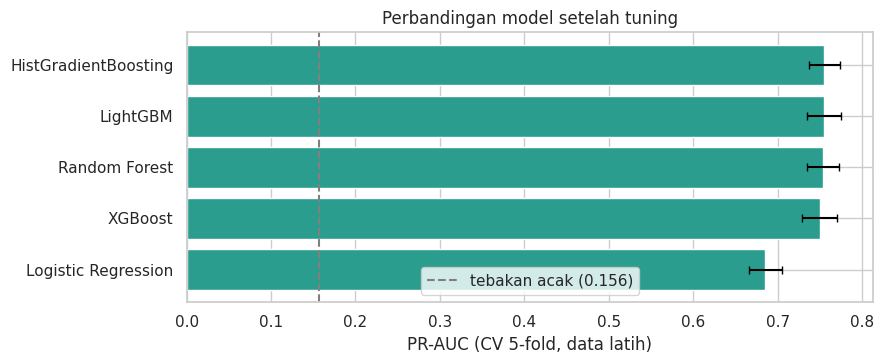

In [8]:
# Hasil pencarian: kandidat terbaik tiap model (berdasarkan PR-AUC CV)
ringkas_cari = pd.DataFrame({
    nama: {"PR-AUC CV (terbaik)": h.loc[0, "pr_auc"], "std antar fold": h.loc[0, "pr_auc_std"],
           "ROC-AUC CV": h.loc[0, "roc_auc"],
           "PR-AUC kandidat terburuk": h["pr_auc"].min(), "rata-rata waktu/kandidat (dtk)": h["detik"].mean()}
    for nama, h in hasil_cari.items()}).T.sort_values("PR-AUC CV (terbaik)", ascending=False)
display(ringkas_cari.round(4))

params_terbaik = {nama: h.loc[0, "params"] for nama, h in hasil_cari.items()}
for nama, p in params_terbaik.items():
    print(f"{nama:22s}", p)

fig, ax = plt.subplots(figsize=(9, 3.8))
urut = ringkas_cari.index[::-1]
ax.barh(urut, ringkas_cari.loc[urut, "PR-AUC CV (terbaik)"], xerr=ringkas_cari.loc[urut, "std antar fold"], capsize=3, color="#2a9d8f")
ax.axvline(y_train.mean(), color="gray", ls="--", label=f"tebakan acak ({y_train.mean():.3f})")
ax.set_xlabel("PR-AUC (CV 5-fold, data latih)"); ax.set_title("Perbandingan model setelah tuning"); ax.legend()
plt.tight_layout(); plt.show()

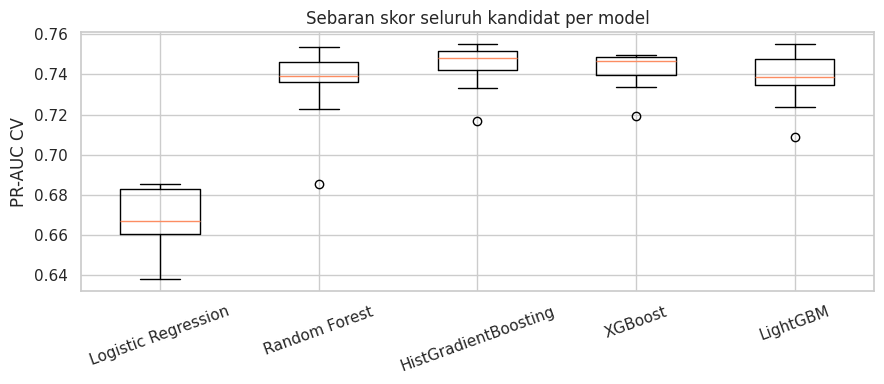

In [9]:
# Seberapa sensitif tiap model terhadap hiperparameter? Sebaran PR-AUC seluruh kandidat
plt.figure(figsize=(9, 4))
data_box = [h["pr_auc"].values for h in hasil_cari.values()]
plt.boxplot(data_box, labels=list(hasil_cari), vert=True); plt.xticks(rotation=20)
plt.ylabel("PR-AUC CV"); plt.title("Sebaran skor seluruh kandidat per model")
plt.tight_layout(); plt.show()

**Interpretasi hasil tuning:**
- **Empat model berbasis pohon praktis setara.** PR-AUC CV berkisar 0,7497 (XGBoost) sampai 0,7551 (HistGradientBoosting). Selisih terbesar 0,005 jauh di bawah simpangan baku antar fold (±0,018–0,021), jadi urutan di antara mereka **tidak bisa dianggap bermakna**.
- **Logistic Regression tertinggal jelas:** 0,6854, sekitar 0,07 di bawah model pohon (hampir 4 kali simpangan baku fold). Ada pola non-linear dan interaksi antar fitur yang tidak tertangkap model linear. Ini membenarkan alasan memakai model pohon.
- **Tuning berpengaruh.** Kandidat terburuk Random Forest 0,686 vs terbaik 0,754; Logistic Regression 0,638 vs 0,685; model boosting 0,709–0,719 vs 0,750–0,755 (lihat boxplot). Memakai hiperparameter bawaan berisiko mendapat hasil di ujung bawah rentang itu.
- **Kelima model memilih konfigurasi tanpa bobot kelas** (`class_weight=None` atau `scale_pos_weight=1`). Ini searah dengan temuan notebook preprocessing 8.6 bahwa bobot kelas tidak memperbaiki kualitas peringkat. Ketidakseimbangan ditangani lewat pemilihan ambang (bagian 5).
- Waktu: Random Forest paling lambat (±10 dtk per kandidat pada 1 CPU), LightGBM tercepat (±1,5 dtk).

# **5. PELATIHAN AKHIR, ENSEMBLE, DAN AMBANG KEPUTUSAN**

Untuk tiap model, parameter terbaik dipakai untuk:
1. **Melatih ulang pada seluruh data latih** (model final), disimpan ke `model_<model>.joblib`.
2. **Membuat prediksi out-of-fold (OOF)** dengan CV yang sama, disimpan ke `oof_<model>.npy`. Setiap baris latih diprediksi oleh model yang **tidak pernah melihat baris itu**, jadi OOF adalah perkiraan jujur performa pada data baru tanpa menyentuh data uji.

OOF dipakai untuk (a) membuat ensemble dan (b) memilih **ambang keputusan** yang memaksimalkan F1. Ambang bawaan 0,5 kurang cocok karena hanya 15,6% sesi yang membeli.

In [10]:
modelku, oof = {}, {}
for nama in MODELS:
    p_model = os.path.join(CKPT_DIR, f"model_{slug(nama)}.joblib")
    p_oof = os.path.join(CKPT_DIR, f"oof_{slug(nama)}.npy")
    t0 = time.time()
    if os.path.exists(p_model) and os.path.exists(p_oof):
        modelku[nama], oof[nama] = joblib.load(p_model), np.load(p_oof)
        print(f"[SKIP] {nama}: model dan OOF dimuat dari checkpoint")
        continue
    if not os.path.exists(p_oof):
        oof[nama] = cross_val_predict(buat_pipeline(nama, params_terbaik[nama]), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
        simpan_npy(p_oof, oof[nama])
    else:
        oof[nama] = np.load(p_oof)
    modelku[nama] = buat_pipeline(nama, params_terbaik[nama]).fit(X_train, y_train)
    simpan_joblib(p_model, modelku[nama])
    print(f"[SELESAI] {nama}: model final + OOF disimpan ({time.time() - t0:.1f} dtk)")

# Ensemble soft voting: rata-rata probabilitas 3 model dengan PR-AUC CV tertinggi
anggota = list(ringkas_cari.index[:3])
oof["Soft voting (3 terbaik)"] = np.mean([oof[n] for n in anggota], axis=0)
print("\nAnggota ensemble:", anggota)

ambang = {n: ambang_f1_terbaik(y_train, p) for n, p in oof.items()}
tabel_oof = pd.DataFrame({n: metrik(y_train, p, ambang[n]) for n, p in oof.items()}).T.sort_values("PR-AUC", ascending=False)
print("\nPerforma OOF pada data latih (ambang dipilih dari OOF ini):")
display(tabel_oof.round(4))

[SELESAI] Logistic Regression: model final + OOF disimpan (0.4 dtk)


[SELESAI] Random Forest: model final + OOF disimpan (15.5 dtk)


[SELESAI] HistGradientBoosting: model final + OOF disimpan (8.1 dtk)


[SELESAI] XGBoost: model final + OOF disimpan (1.9 dtk)


[SELESAI] LightGBM: model final + OOF disimpan (2.1 dtk)

Anggota ensemble: ['HistGradientBoosting', 'LightGBM', 'Random Forest']

Performa OOF pada data latih (ambang dipilih dari OOF ini):


,PR-AUC,ROC-AUC,ambang,precision,recall,F1
Soft voting (3 terbaik),0.7551,0.9339,0.3480,0.6623,0.7261,0.6927
HistGradientBoosting,0.7526,0.9323,0.3461,0.6633,0.7228,0.6918
LightGBM,0.7523,0.9334,0.3219,0.6530,0.7438,0.6955
Random Forest,0.7518,0.9313,0.3790,0.6638,0.7117,0.6869
XGBoost,0.7479,0.9313,0.3431,0.6547,0.7320,0.6912
Logistic Regression,0.6835,0.9124,0.2855,0.6386,0.7110,0.6729


**Interpretasi pelatihan akhir:**
- **Ambang F1 terbaik** untuk model pohon ada di 0,32–0,38 dan untuk Logistic Regression 0,29, jauh di bawah 0,5. Dengan hanya 15,6% pembeli, ambang 0,5 akan melewatkan banyak pembeli. Ambang ini dipilih dari OOF, bukan dari data uji, dan bisa diganti sesuai biaya (mis. bila menawarkan promo ke non-pembeli murah, turunkan ambang untuk menaikkan recall).
- **Ensemble hampir tidak menambah apa-apa.** PR-AUC OOF soft voting 0,7551 vs HistGradientBoosting 0,7526 (+0,0025), jauh di bawah simpangan baku fold. Model-model pohon belajar pola yang sangat mirip sehingga rata-rata probabilitasnya kurang memberi variasi baru.
- Anggota ensemble adalah tiga model CV tertinggi (HistGradientBoosting, LightGBM, Random Forest); XGBoost tidak masuk.

# **6. EVALUASI PADA DATA UJI**

Data uji dipakai **satu kali** di sini. Semua model, parameter, dan ambang sudah dipilih dari data latih. Model "terbaik" ditentukan dari **PR-AUC CV pada data latih**, bukan dari skor uji, supaya data uji tetap menjadi ukuran yang jujur.

In [11]:
proba_uji = {n: modelku[n].predict_proba(X_test)[:, 1] for n in MODELS}
proba_uji["Soft voting (3 terbaik)"] = np.mean([proba_uji[n] for n in anggota], axis=0)

baris = {"Dummy (prior)": {"PR-AUC": pr_dummy, "ROC-AUC": 0.5}}
for n, p in proba_uji.items():
    baris[n] = metrik(y_test, p, ambang[n])
tabel_uji = pd.DataFrame(baris).T.sort_values("PR-AUC", ascending=False)
display(tabel_uji.round(4))

# Model terbaik menurut CV (bukan menurut data uji)
terbaik_cv = ringkas_cari.index[0]
print(f"Model terbaik menurut CV data latih: {terbaik_cv}")

# Selisih performa latih(OOF) vs uji: indikator overfit atau ketidakcocokan pembagian data
gap = pd.DataFrame({"PR-AUC OOF (latih)": tabel_oof["PR-AUC"], "PR-AUC uji": tabel_uji["PR-AUC"]}).dropna()
gap["selisih (uji - OOF)"] = gap["PR-AUC uji"] - gap["PR-AUC OOF (latih)"]
display(gap.round(4))

,PR-AUC,ROC-AUC,ambang,precision,recall,F1
LightGBM,0.7614,0.9378,0.3219,0.6392,0.7513,0.6907
Soft voting (3 terbaik),0.7592,0.9364,0.3480,0.6580,0.7304,0.6923
XGBoost,0.7562,0.9386,0.3431,0.6437,0.7330,0.6854
HistGradientBoosting,0.7560,0.9361,0.3461,0.6620,0.7487,0.7027
Random Forest,0.7527,0.9319,0.3790,0.6667,0.7016,0.6837
Logistic Regression,0.6961,0.9219,0.2855,0.6259,0.7225,0.6707
Dummy (prior),0.1565,0.5000,NaN,NaN,NaN,NaN


Model terbaik menurut CV data latih: HistGradientBoosting


,PR-AUC OOF (latih),PR-AUC uji,selisih (uji - OOF)
HistGradientBoosting,0.7526,0.7560,0.0033
LightGBM,0.7523,0.7614,0.0091
Logistic Regression,0.6835,0.6961,0.0126
Random Forest,0.7518,0.7527,0.0010
Soft voting (3 terbaik),0.7551,0.7592,0.0041
XGBoost,0.7479,0.7562,0.0083


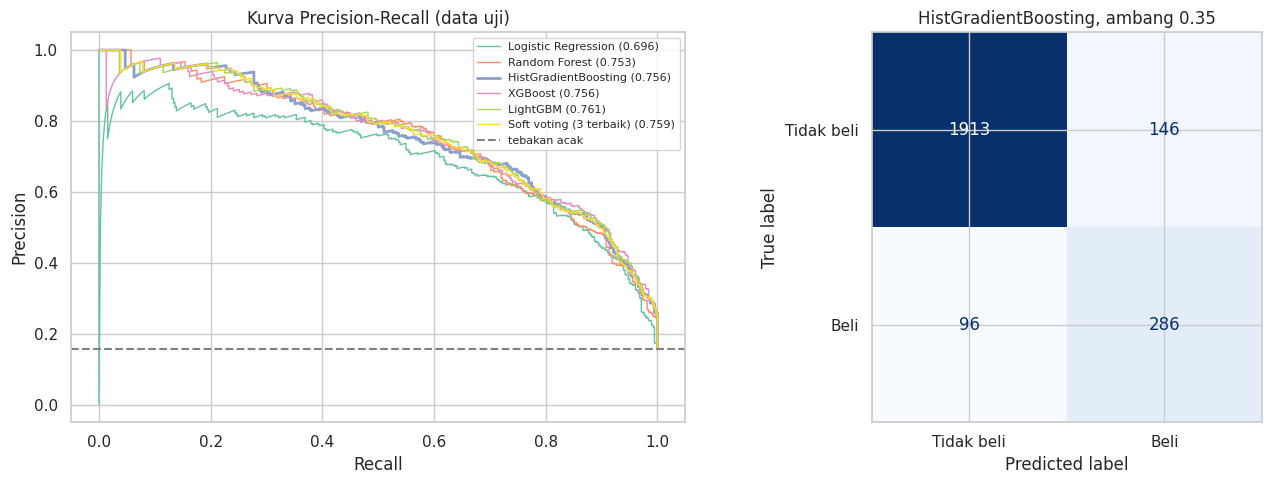

Dari 382 sesi pembeli di data uji, 286 terdeteksi (recall 74.9%); 146 sesi bukan pembeli ikut ditandai.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Kurva Precision-Recall
for n, p in proba_uji.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rc, pr, label=f"{n} ({average_precision_score(y_test, p):.3f})", lw=2 if n == terbaik_cv else 1)
axes[0].axhline(y_test.mean(), color="gray", ls="--", label="tebakan acak")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Kurva Precision-Recall (data uji)"); axes[0].legend(fontsize=8)

# Matriks konfusi model terbaik pada ambang dari OOF
pred = (proba_uji[terbaik_cv] >= ambang[terbaik_cv]).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Tidak beli", "Beli"]).plot(ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title(f"{terbaik_cv}, ambang {ambang[terbaik_cv]:.2f}")
plt.tight_layout(); plt.show()

cm = confusion_matrix(y_test, pred)
print(f"Dari {cm[1].sum()} sesi pembeli di data uji, {cm[1, 1]} terdeteksi (recall {cm[1, 1] / cm[1].sum():.1%}); {cm[0, 1]} sesi bukan pembeli ikut ditandai.")

**Interpretasi evaluasi data uji:**
- Semua model jauh di atas tebakan acak (PR-AUC 0,157): 0,70 (Logistic Regression) sampai 0,76 (model pohon).
- **Model terbaik menurut CV adalah HistGradientBoosting**: PR-AUC uji 0,7560; pada ambang 0,35 precision 0,662, recall 0,749, F1 0,703. Dari 382 sesi pembeli di data uji, 286 terdeteksi dan 146 sesi bukan pembeli ikut ditandai.
- LightGBM memiliki skor uji tertinggi (0,7614) dan soft voting 0,7592, tetapi selisihnya dengan HistGradientBoosting (≤ 0,006) jauh di bawah simpangan baku CV. Memilih model berdasarkan skor uji berarti memakai data uji untuk seleksi, jadi pilihan tetap mengikuti CV.
- **Tidak ada tanda overfit:** selisih skor uji dikurangi OOF berkisar +0,001 sampai +0,013 (uji sedikit lebih tinggi, kemungkinan kebetulan pada pembagian ini).
- Logistic Regression tertinggal sekitar 0,06 dari model terbaik, konsisten dengan hasil CV.

# **7. UJI TANPA `PAGEVALUES` DAN INTERPRETASI MODEL**

`PageValues` adalah nilai rata-rata halaman yang dikunjungi sebelum transaksi, dan di notebook preprocessing terbukti sangat dominan sekaligus **berpotensi bocor** (nilainya dihitung dari hasil transaksi). Karena itu setiap model juga dinilai **tanpa fitur ini**, memakai hiperparameter terbaik yang sama (tanpa mencari ulang).

In [13]:
abl = {}
for nama in MODELS:
    p_abl = os.path.join(CKPT_DIR, f"ablasi_{slug(nama)}.json")
    if os.path.exists(p_abl):
        abl[nama] = muat_json(p_abl); print(f"[SKIP] ablasi {nama}"); continue
    r = cross_validate(buat_pipeline(nama, params_terbaik[nama], drop_pagevalues=True), X_train, y_train, cv=cv,
                       scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
    abl[nama] = {"pr_auc": float(r["test_pr_auc"].mean()), "std": float(r["test_pr_auc"].std()), "roc_auc": float(r["test_roc_auc"].mean())}
    simpan_json(p_abl, abl[nama]); print(f"[SELESAI] ablasi {nama}")

tabel_abl = pd.DataFrame({
    "PR-AUC dengan PageValues": ringkas_cari["PR-AUC CV (terbaik)"],
    "PR-AUC tanpa PageValues": pd.Series({n: v["pr_auc"] for n, v in abl.items()}),
    "ROC-AUC tanpa PageValues": pd.Series({n: v["roc_auc"] for n, v in abl.items()}),
})
tabel_abl["penurunan"] = tabel_abl["PR-AUC dengan PageValues"] - tabel_abl["PR-AUC tanpa PageValues"]
display(tabel_abl.sort_values("PR-AUC tanpa PageValues", ascending=False).round(4))
print(f"Pembanding tebakan acak: {y_train.mean():.3f}")

[SELESAI] ablasi Logistic Regression


[SELESAI] ablasi Random Forest


[SELESAI] ablasi HistGradientBoosting


[SELESAI] ablasi XGBoost


[SELESAI] ablasi LightGBM


,PR-AUC dengan PageValues,PR-AUC tanpa PageValues,ROC-AUC tanpa PageValues,penurunan
LightGBM,0.7549,0.3860,0.7804,0.3689
HistGradientBoosting,0.7551,0.3854,0.7782,0.3697
Random Forest,0.7536,0.3755,0.7731,0.3781
XGBoost,0.7497,0.3713,0.7763,0.3784
Logistic Regression,0.6854,0.3416,0.7497,0.3438


Pembanding tebakan acak: 0.156


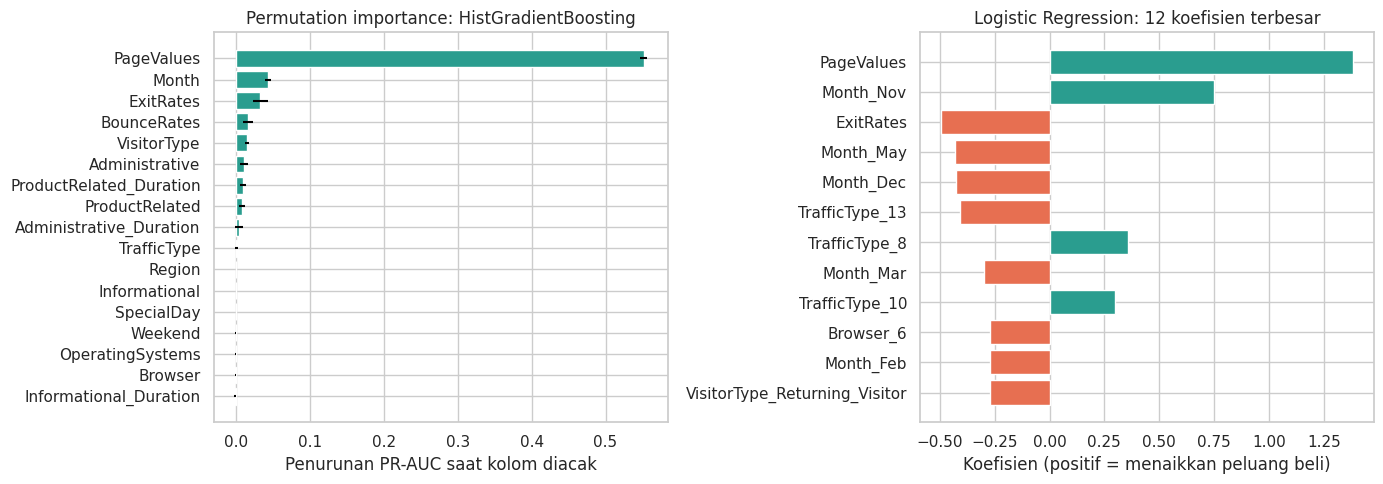

5 fitur teratas (permutation importance):
PageValues     0.5514
Month          0.0435
ExitRates      0.0332
BounceRates    0.0159
VisitorType    0.0152


In [14]:
# (a) Permutation importance pada data uji untuk model terbaik menurut CV:
#     seberapa turun PR-AUC bila satu kolom asli diacak. Dihitung pada kolom MENTAH, jadi mudah dibaca.
pi = permutation_importance(modelku[terbaik_cv], X_test, y_test, scoring="average_precision",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp_std = pd.Series(pi.importances_std, index=X_test.columns)[imp.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(imp.index, imp.values, xerr=imp_std.values, color="#2a9d8f")
axes[0].set_title(f"Permutation importance: {terbaik_cv}"); axes[0].set_xlabel("Penurunan PR-AUC saat kolom diacak")

# (b) Koefisien Logistic Regression terbaik (arah pengaruh, pada skala fitur terstandar)
lr = modelku["Logistic Regression"]
nama_fitur = lr.named_steps["prep"].get_feature_names_out()
koef = pd.Series(lr.named_steps["clf"].coef_[0], index=nama_fitur)
top = koef.reindex(koef.abs().sort_values(ascending=False).index[:12])[::-1]
axes[1].barh(top.index, top.values, color=["#2a9d8f" if v > 0 else "#e76f51" for v in top.values])
axes[1].set_title("Logistic Regression: 12 koefisien terbesar"); axes[1].set_xlabel("Koefisien (positif = menaikkan peluang beli)")
plt.tight_layout(); plt.show()

print("5 fitur teratas (permutation importance):")
print(imp[::-1].head(5).round(4).to_string())

**Interpretasi uji tanpa `PageValues` dan pentingnya fitur:**
- **Tanpa `PageValues`, PR-AUC turun hampir separuh**, dari ≈ 0,75 menjadi 0,34–0,39 (turun 0,34–0,38). Model masih sekitar 2,2–2,5 kali lebih baik dari tebakan acak (0,156), jadi ada sinyal dari perilaku penjelajahan, tetapi jauh lebih lemah.
- Urutan model tanpa `PageValues` serupa: LightGBM 0,386, HistGradientBoosting 0,385, Random Forest 0,376, XGBoost 0,371, Logistic Regression 0,342. Selisih antar model pohon kecil (≤ 0,015). Jarak model pohon dengan Logistic Regression mengecil menjadi ≈ 0,04; sebagian keunggulan model pohon tampaknya terkait `PageValues` (dugaan, belum diuji langsung).
- **Permutation importance** (HistGradientBoosting, data uji): `PageValues` menurunkan PR-AUC 0,551 saat diacak, jauh di atas `Month` (0,044), `ExitRates` (0,033), `BounceRates` (0,016), dan `VisitorType` (0,015). Fitur lain berkontribusi kecil.
- **Catatan penggunaan:** `PageValues` dihitung dari data transaksi sehingga berpotensi bocor bila model dipakai memprediksi sesi yang sedang berjalan. Varian **dengan** `PageValues` cocok untuk analisis dan perbandingan; untuk prediksi saat sesi berlangsung, patokan realistisnya adalah varian **tanpa** `PageValues` (PR-AUC ≈ 0,39).

# **8. MENYIMPAN HASIL DAN KESIMPULAN**

In [15]:
hasil_dir = os.path.join(CKPT_DIR, "hasil")
os.makedirs(hasil_dir, exist_ok=True)

tabel_uji.round(4).to_csv(os.path.join(hasil_dir, "hasil_uji.csv"))
ringkas_cari.round(4).to_csv(os.path.join(hasil_dir, "hasil_cv_tuning.csv"))
tabel_abl.round(4).to_csv(os.path.join(hasil_dir, "hasil_tanpa_pagevalues.csv"))
simpan_json(os.path.join(hasil_dir, "parameter_terbaik.json"), {n: bersihkan(p) for n, p in params_terbaik.items()})
simpan_joblib(os.path.join(hasil_dir, "model_terbaik.joblib"),
              {"nama": terbaik_cv, "model": modelku[terbaik_cv], "ambang": ambang[terbaik_cv]})

print("Isi folder hasil:", sorted(os.listdir(hasil_dir)))
print("\nDaftar seluruh checkpoint:")
display(status_checkpoint())

# Salinan zip untuk diunduh (di Colab). Checkpoint asli tetap aman di Drive.
with zipfile.ZipFile("hasil_modelling.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in os.listdir(hasil_dir):
        z.write(os.path.join(hasil_dir, f), arcname=f"hasil_modelling/{f}")
try:
    from google.colab import files
    files.download("hasil_modelling.zip")
except ImportError:
    print("Bukan Google Colab: unduhan dilewati. Zip ada di hasil_modelling.zip")

Isi folder hasil: ['hasil_cv_tuning.csv', 'hasil_tanpa_pagevalues.csv', 'hasil_uji.csv', 'model_terbaik.joblib', 'parameter_terbaik.json']

Daftar seluruh checkpoint:


,file,ukuran_KB
0,ablasi_histgradientboosting.json,0.1
1,ablasi_lightgbm.json,0.1
2,ablasi_logistic_regression.json,0.1
3,ablasi_random_forest.json,0.1
4,ablasi_xgboost.json,0.1
5,cari_histgradientboosting.jsonl,4.1
6,cari_lightgbm.jsonl,4.5
7,cari_logistic_regression.jsonl,2.8
8,cari_random_forest.jsonl,3.5
9,cari_xgboost.jsonl,4.5


Bukan Google Colab: unduhan dilewati. Zip ada di hasil_modelling.zip


## Kesimpulan

| Model | PR-AUC CV (latih) | PR-AUC uji | Catatan |
|---|---|---|---|
| Dummy (prior) | – | 0,157 | Batas bawah |
| Logistic Regression | 0,685 | 0,696 | Dapat dibaca, tertinggal ±0,06 |
| Random Forest | 0,754 | 0,753 | Paling lambat dilatih |
| **HistGradientBoosting** | **0,755** | **0,756** | **Terbaik menurut CV, dipilih** |
| XGBoost | 0,750 | 0,756 | Setara |
| LightGBM | 0,755 | 0,761 | Setara dan tercepat |
| Soft voting (3 terbaik) | 0,755 (OOF) | 0,759 | Tidak menambah nilai berarti |

**Rekomendasi**
1. **Model utama: HistGradientBoosting** (terbaik menurut CV). XGBoost, LightGBM, dan Random Forest tidak bisa dibedakan darinya secara statistik; bila kecepatan latih penting, LightGBM adalah alternatif yang setara. Ensemble tidak diperlukan.
2. **Ambang keputusan ±0,35** (dari OOF) memberi recall ≈ 0,75 dan precision ≈ 0,66. Sesuaikan dengan biaya intervensi bisnis.
3. Untuk prediksi pada sesi yang sedang berjalan, gunakan varian **tanpa `PageValues`** dan harapkan PR-AUC ≈ 0,39, bukan 0,75.

**Keterbatasan**
- Hanya satu pembagian latih/uji; data uji hanya memuat 382 pembeli, sehingga selisih kecil antar model tidak bermakna.
- `N_ITER = 12` termasuk kecil; naikkan (mis. 30) bila waktu Colab cukup. Mengubah `N_ITER` membuat folder checkpoint baru, sehingga pencarian dimulai dari awal.
- Pembagian dilakukan acak, bukan berdasarkan waktu. Performa pada bulan yang belum pernah dilihat model belum diuji.
- Probabilitas belum dikalibrasi; gunakan sebagai peringkat atau lewat ambang, bukan sebagai peluang absolut.

**Langkah lanjut:** kalibrasi probabilitas, validasi per bulan, pemilihan ambang berbasis biaya, dan SHAP untuk penjelasan per sesi.